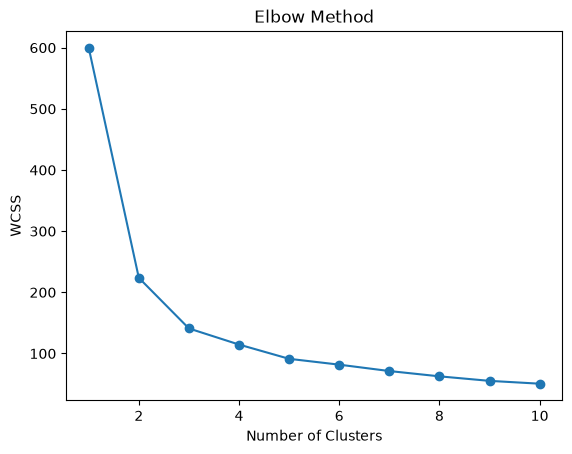

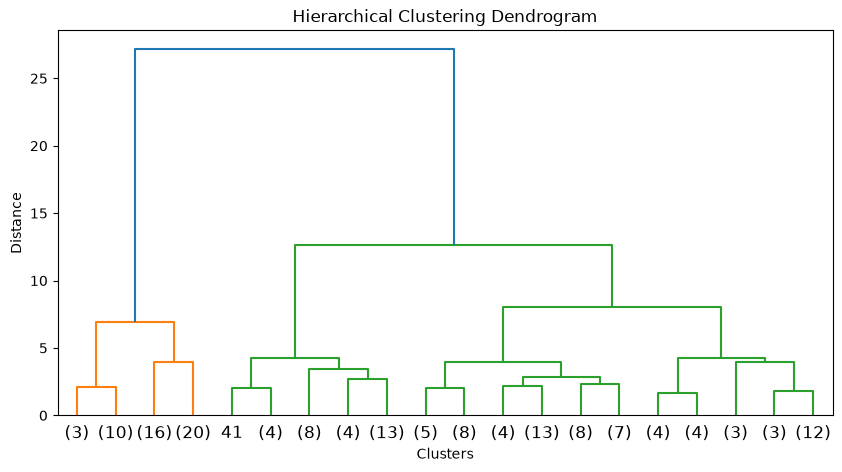

K-Means Cluster Counts:
KMeans_Cluster
0    53
1    50
2    47
Name: count, dtype: int64

Hierarchical Cluster Counts:
Hierarchical_Cluster
0    71
1    49
2    30
Name: count, dtype: int64

K-Means Silhouette Score: 0.459
Hierarchical Silhouette Score: 0.446


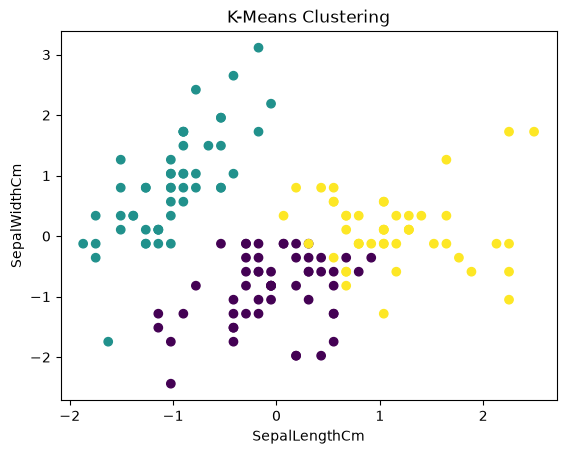


Cluster Assignments:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species  \
0   1            5.1           3.5            1.4           0.2  Iris-setosa   
1   2            4.9           3.0            1.4           0.2  Iris-setosa   
2   3            4.7           3.2            1.3           0.2  Iris-setosa   
3   4            4.6           3.1            1.5           0.2  Iris-setosa   
4   5            5.0           3.6            1.4           0.2  Iris-setosa   

   KMeans_Cluster  Hierarchical_Cluster  
0               1                     1  
1               1                     1  
2               1                     1  
3               1                     1  
4               1                     1  


In [2]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

# 1. Load Iris dataset
df = pd.read_csv("Iris.csv")

# Remove ID and Species columns
X = df.select_dtypes(include="number")
X = X.drop(columns=["Id", "id"], errors="ignore")

# 2. Feature scaling
X_scaled = StandardScaler().fit_transform(X)

# 3. Elbow Method
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

# 4. Dendrogram
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode="lastp", p=20)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Clusters")
plt.ylabel("Distance")
plt.show()

# 5. Apply K-Means Clustering
k = 3

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

# 6. Apply Hierarchical Clustering
hierarchical = AgglomerativeClustering(n_clusters=k)
hierarchical_labels = hierarchical.fit_predict(X_scaled)

# 7. Analyze clusters
df["KMeans_Cluster"] = kmeans_labels
df["Hierarchical_Cluster"] = hierarchical_labels

print("K-Means Cluster Counts:")
print(df["KMeans_Cluster"].value_counts().sort_index())

print("\nHierarchical Cluster Counts:")
print(df["Hierarchical_Cluster"].value_counts().sort_index())

print("\nK-Means Silhouette Score:",
      round(silhouette_score(X_scaled, kmeans_labels), 3))

print("Hierarchical Silhouette Score:",
      round(silhouette_score(X_scaled, hierarchical_labels), 3))

# 8. Visualize K-Means clusters
plt.scatter(X_scaled[:, 0], X_scaled[:, 1],
            c=kmeans_labels, cmap="viridis")

plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.title("K-Means Clustering")
plt.show()

# 9. Display results
print("\nCluster Assignments:")
print(df.head())

df.to_csv("clustering_results.csv", index=False)
